## Crowdfunding Project: Exploration and Data Quality

This notebook explores Kickstarter crowdfunding projects through additional visualizations and statistical analysis.

The goal is to investigate patterns in project funding, backer participation, campaign duration, and project success.

This analysis is separate from the work completed in the team's original notebook.

In [2]:
# Importing all of the relevant programs we will need for this project. 

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt 
import csv 
import numpy as np
import plotly.express as px

# Reading in the data set and displaing the first 5 rows of the data set. 
# Fixed a UnicodeError: we used the csv module from Python to process the code line by line 
# without worrying about whether a row has 13, 14, or 17 fields 
# due to certain inconsistencies in the number of columns in some of the rows. 

df = pd.DataFrame(
    list(csv.reader(open("kickstarter.csv", encoding="cp1252")))
)

## Overview of the data frame, including the numeber of rows and columns, data types, and memory usage. 

display(df.head())
print("Dataset shape:", df.shape)
display(df.info())
display(df.describe(include="all").T)

# Dropping columns with missing values
df = df.dropna(axis=1)

#Looking at 13, 14, 15, 16 differences from the rest

/var/folders/cx/1bd5ng0x13sfdp4d82d7wfk40000gn/T/ipykernel_3642/113153825.py:13: Pandas4Warning: Constructing a DataFrame from a list of sequences with mismatched lengths is deprecated and will raise in a future version. The shorter sequences are currently padded with NaN; make all sequences the same length before constructing instead.
  df = pd.DataFrame(


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
0,ID,name,category,main_category,currency,deadline,goal,launched,pledged,state,backers,country,usd pledged,NaN,NaN,NaN,NaN
1,1000002330,The Songs of Adelaide & Abullah,Poetry,Publishing,GBP,2015-10-09 11:36:00,1000,2015-08-11 12:12:28,0,failed,0,GB,0,NaN,NaN,NaN,NaN
2,1000004038,Where is Hank?,Narrative Film,Film & Video,USD,2013-02-26 00:20:50,45000,2013-01-12 00:20:50,220,failed,3,US,220,NaN,NaN,NaN,NaN
3,1000007540,ToshiCapital Rekordz Needs Help to Complete Album,Music,Music,USD,2012-04-16 04:24:11,5000,2012-03-17 03:24:11,1,failed,1,US,1,NaN,NaN,NaN,NaN
4,1000011046,Community Film Project: The Art of Neighborhoo...,Film & Video,Film & Video,USD,2015-08-29 01:00:00,19500,2015-07-04 08:35:03,1283,canceled,14,US,1283,NaN,NaN,NaN,NaN


Dataset shape: (323751, 17)
<class 'pandas.DataFrame'>
RangeIndex: 323751 entries, 0 to 323750
Data columns (total 17 columns):
 #   Column  Non-Null Count   Dtype
---  ------  --------------   -----
 0   0       323751 non-null  str  
 1   1       323751 non-null  str  
 2   2       323751 non-null  str  
 3   3       323751 non-null  str  
 4   4       323751 non-null  str  
 5   5       323751 non-null  str  
 6   6       323751 non-null  str  
 7   7       323751 non-null  str  
 8   8       323751 non-null  str  
 9   9       323751 non-null  str  
 10  10      323751 non-null  str  
 11  11      323751 non-null  str  
 12  12      323751 non-null  str  
 13  13      625 non-null     str  
 14  14      624 non-null     str  
 15  15      624 non-null     str  
 16  16      624 non-null     str  
dtypes: str(17)
memory usage: 42.0 MB


None

,count,unique,top,freq
0,323751,323751,ID,1
1,323751,321617,New EP/Music Development,41
2,323751,772,Product Design,17477
3,323751,121,Film & Video,57679
4,323751,38,USD,260298
5,323751,294814,USD,508
6,323751,8189,5000,25520
7,323751,322799,5000,60
8,323751,55599,0,45784
9,323751,411,failed,168221


In [3]:
# Information about the data frame, including the number of rows and columns, data types, and memory usage.
df.columns 
df.columns = df.iloc[0]  # Set the first row as column names
df = df.iloc[1:]  # Remove the first row

In [4]:
df.head()
df.columns 

# Remove leading and trailing spaces from column names
df.columns = df.columns.str.strip()

# Check the cleaned column names
print(df.columns.tolist())

['ID', 'name', 'category', 'main_category', 'currency', 'deadline', 'goal', 'launched', 'pledged', 'state', 'backers', 'country', 'usd pledged']


In [5]:
# Create a separate DataFrame for our analysis
analysis_df = df.copy()

# Remove extra columns created by inconsistent CSV rows
analysis_df = analysis_df.loc[
    :, ~analysis_df.columns.str.startswith("Unnamed")
].copy()

# Remove spaces from text fields
for col in ["state", "launched", "deadline"]:
    analysis_df[col] = analysis_df[col].astype("string").str.strip()

# Keep projects with clear completed outcomes
analysis_df = analysis_df[
    analysis_df["state"].isin(["successful", "failed"])
].copy()

# Convert campaign dates
analysis_df["launched"] = pd.to_datetime(
    analysis_df["launched"], errors="coerce"
)
analysis_df["deadline"] = pd.to_datetime(
    analysis_df["deadline"], errors="coerce"
)

# Calculate campaign duration in days
analysis_df["campaign_days"] = (
    analysis_df["deadline"] - analysis_df["launched"]
).dt.total_seconds() / (24 * 60 * 60)

# Keep records with valid, positive campaign durations
analysis_df = analysis_df[
    analysis_df["campaign_days"].notna()
    & (analysis_df["campaign_days"] > 0)
].copy()

print("Projects available for analysis:", len(analysis_df))
print("\nOutcome counts:")
print(analysis_df["state"].value_counts())
print("\nCampaign duration summary:")
print(analysis_df["campaign_days"].describe())

Projects available for analysis: 281302

Outcome counts:
state
failed        168221
successful    113081
Name: count, dtype: Int64

Campaign duration summary:
count    281302.000000
mean         34.159813
std          12.890952
min           1.000000
25%          30.000000
50%          30.000000
75%          36.941071
max          92.000000
Name: campaign_days, dtype: float64


In [8]:
top_10_categories = df['category'].value_counts().head(10).index
top_10_categories 

filtered_df = df[df['category'].isin(top_10_categories)]
filtered_df 

#What percentage do the categories take up in the data set. 

0,ID,name,category,main_category,currency,deadline,goal,launched,pledged,state,backers,country,usd pledged
3,1000007540,ToshiCapital Rekordz Needs Help to Complete Album,Music,Music,USD,2012-04-16 04:24:11,5000,2012-03-17 03:24:11,1,failed,1,US,1
4,1000011046,Community Film Project: The Art of Neighborhoo...,Film & Video,Film & Video,USD,2015-08-29 01:00:00,19500,2015-07-04 08:35:03,1283,canceled,14,US,1283
6,1000023410,Support Solar Roasted Coffee & Green Energy! ...,Food,Food,USD,2014-12-21 18:30:44,1000,2014-12-01 18:30:44,1205,successful,16,US,1205
8,1000034518,SPIN - Premium Retractable In-Ear Headphones w...,Product Design,Design,USD,2014-05-29 18:14:43,125000,2014-04-24 18:14:43,8233,canceled,58,US,8233
9,100004195,STUDIO IN THE SKY - A Documentary Feature Film...,Documentary,Film & Video,USD,2014-08-10 21:55:48,65000,2014-07-11 21:55:48,6240.57,canceled,43,US,6240.57
...,...,...,...,...,...,...,...,...,...,...,...,...,...
323736,999934908,The Manual Bar Blade,Product Design,Design,USD,2015-12-15 06:59:00,3500,2015-11-23 07:33:14,6169,successful,120,US,6169
323740,999955533,Cards and Chit Network Season 2! (Canceled),Tabletop Games,Games,USD,2016-02-23 16:03:27,500,2016-01-24 16:03:27,121,canceled,5,US,121
323743,999971898,Beach Wrestling Documentary,Documentary,Film & Video,NOK,2015-04-28 21:30:33,20000,2015-03-29 21:30:33,21500,successful,36,NO,2698.974335
323744,999972264,Islanda,Documentary,Film & Video,USD,2012-03-16 03:31:10,1700,2012-02-15 04:31:10,25,failed,1,US,25


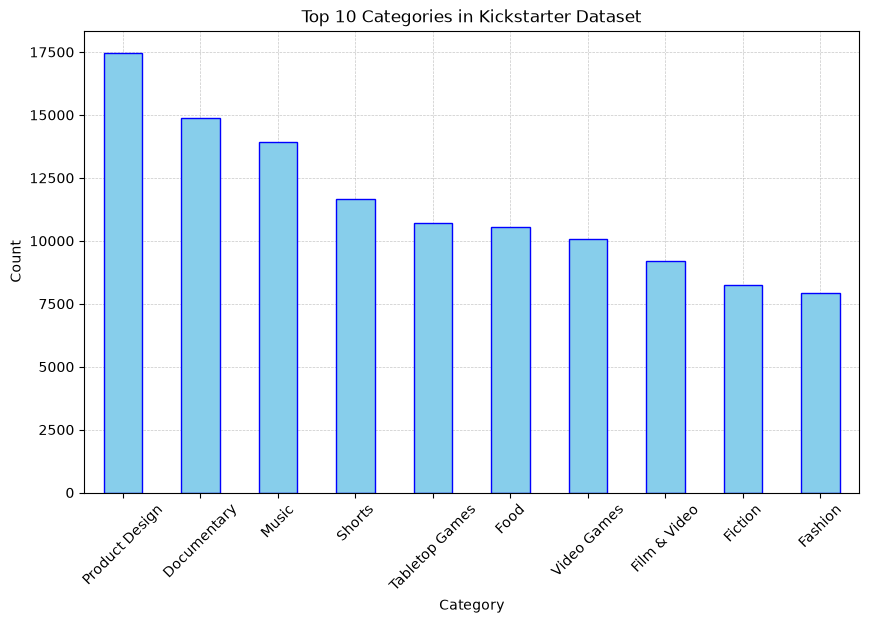

In [9]:
# Filtering the DataFrame to include only the top 10 categories based on their counts.
filtered_df = df[df['category'].isin(top_10_categories)] 
filtered_df

#Needs to show the 10 categories and their counts.

ax = filtered_df['category'].value_counts().plot(kind='bar', figsize=(10, 6), color='skyblue', edgecolor='blue')
plt.title('Top 10 Categories in Kickstarter Dataset')
plt.xlabel('Category')
plt.ylabel('Count') 


ax.grid(True, which='major',axis='both', linestyle='--',linewidth=0.5, alpha=0.7)
plt.xticks(rotation=45) 
ax.set_axisbelow(True)

In [11]:
#Filtering to the Top 5 Most Popular Main Categories in the Kickstarter Dataset.

top_5_main_categories = df['main_category'].value_counts().head(5).index
top_5_main_categories 

filtered_df = df[df['main_category'].isin(top_5_main_categories)]
filtered_df 

#Future Question: What percentage do the main categories categories take up in the data set?

0,ID,name,category,main_category,currency,deadline,goal,launched,pledged,state,backers,country,usd pledged
1,1000002330,The Songs of Adelaide & Abullah,Poetry,Publishing,GBP,2015-10-09 11:36:00,1000,2015-08-11 12:12:28,0,failed,0,GB,0
2,1000004038,Where is Hank?,Narrative Film,Film & Video,USD,2013-02-26 00:20:50,45000,2013-01-12 00:20:50,220,failed,3,US,220
3,1000007540,ToshiCapital Rekordz Needs Help to Complete Album,Music,Music,USD,2012-04-16 04:24:11,5000,2012-03-17 03:24:11,1,failed,1,US,1
4,1000011046,Community Film Project: The Art of Neighborhoo...,Film & Video,Film & Video,USD,2015-08-29 01:00:00,19500,2015-07-04 08:35:03,1283,canceled,14,US,1283
9,100004195,STUDIO IN THE SKY - A Documentary Feature Film...,Documentary,Film & Video,USD,2014-08-10 21:55:48,65000,2014-07-11 21:55:48,6240.57,canceled,43,US,6240.57
...,...,...,...,...,...,...,...,...,...,...,...,...,...
323745,999976312,Angela's Poetry (Canceled),Poetry,Publishing,CAD,2014-09-20 03:46:07,5500,2014-08-06 03:46:07,0,canceled,0,CA,0
323746,999976400,ChknTruk Nationwide Charity Drive 2014 (Canceled),Documentary,Film & Video,USD,2014-10-17 02:35:30,50000,2014-09-17 02:35:30,25,canceled,1,US,25
323747,999977640,The Tribe,Narrative Film,Film & Video,USD,2011-07-19 03:35:14,1500,2011-06-22 03:35:14,155,failed,5,US,155
323748,999986353,Walls of Remedy- New lesbian Romantic Comedy f...,Narrative Film,Film & Video,USD,2010-08-16 05:59:00,15000,2010-07-01 19:40:30,20,failed,1,US,20


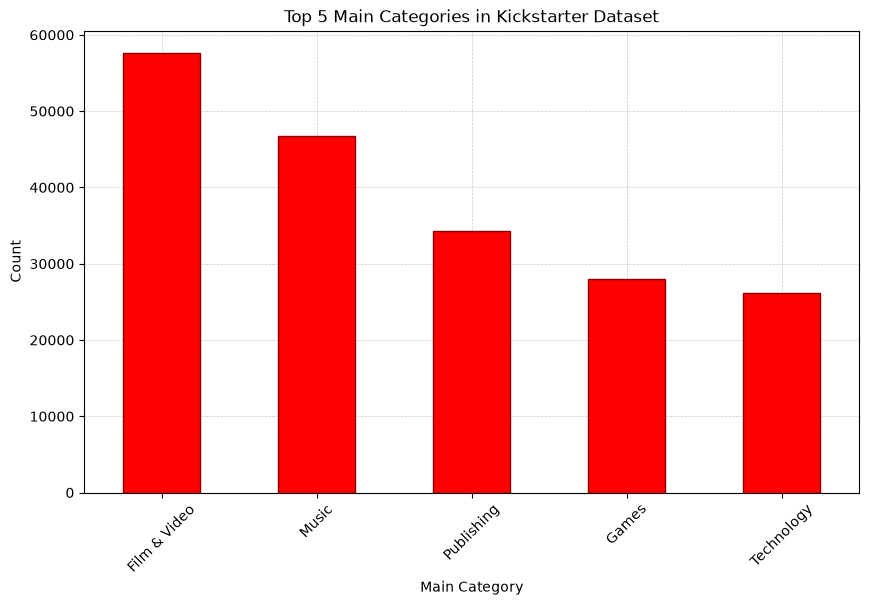

In [12]:
# Filtering the DataFrame to include only the top 5 categories based on their counts.
filtered_df = df[df['main_category'].isin(top_5_main_categories)]  
filtered_df

#Needs to show the 5 categories and their counts.

ax= filtered_df['main_category'].value_counts().plot(kind='bar', figsize=(10, 6), color='red', edgecolor='darkred')
plt.title('Top 5 Main Categories in Kickstarter Dataset')
plt.xlabel('Main Category')
plt.ylabel('Count') 

ax.grid(True, which='major',axis='both', linestyle='--',linewidth=0.5, alpha=0.7)
plt.xticks(rotation=45) 
ax.set_axisbelow(True)

count         2.000000
mean     161875.000000
std      214650.748711
min       10094.000000
25%       85984.500000
50%      161875.000000
75%      237765.500000
max      313656.000000
Name: count, dtype: float64


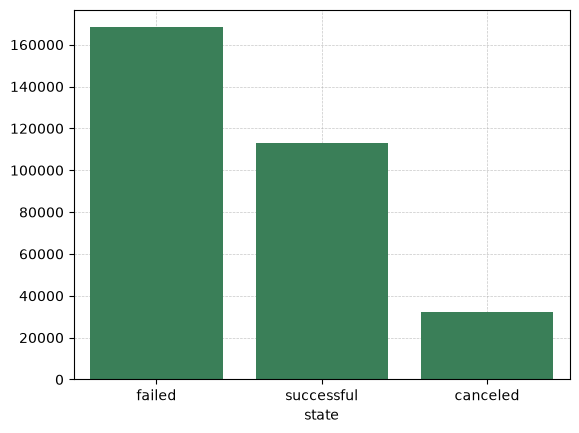

In [26]:
ax= sns.barplot(x=df[df['state'].isin(['successful', 'failed', 'canceled'])]['state']
    .value_counts().index, color='seagreen', y=df[df['state'].isin(['successful', 'failed', 'canceled'])]['state'].value_counts().values)
ax.grid(True, which='major',axis='both', linestyle='--',linewidth=0.5, alpha=0.7)
ax.set_axisbelow(True)

print(df['state'].isin(['successful','failed','canceled']).value_counts().describe())


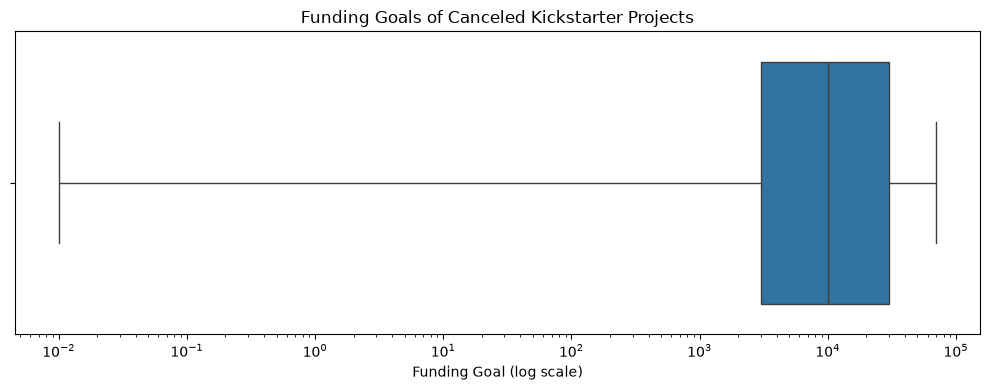

In [41]:
df["goal"] = pd.to_numeric(df["goal"], errors="coerce")
df["state"] = df["state"].astype("string").str.strip()
canceled = df[(df["state"] == "canceled") & (df["goal"] > 0)].copy()

plt.figure(figsize=(10, 4))

sns.boxplot(
    data=canceled,
    x="goal",
    showfliers=False
)

plt.xscale("log")
plt.title("Funding Goals of Canceled Kickstarter Projects")
plt.xlabel("Funding Goal (log scale)")
plt.tight_layout()
plt.show()

In [47]:
df["state"].describe
df["state"].describe()
df["state"].value_counts()


state
failed        168221
successful    113081
canceled       32354
live            4428
undefined       3555
               ...  
296                1
61                 1
179                1
2501               1
2634               1
Name: count, Length: 410, dtype: Int64

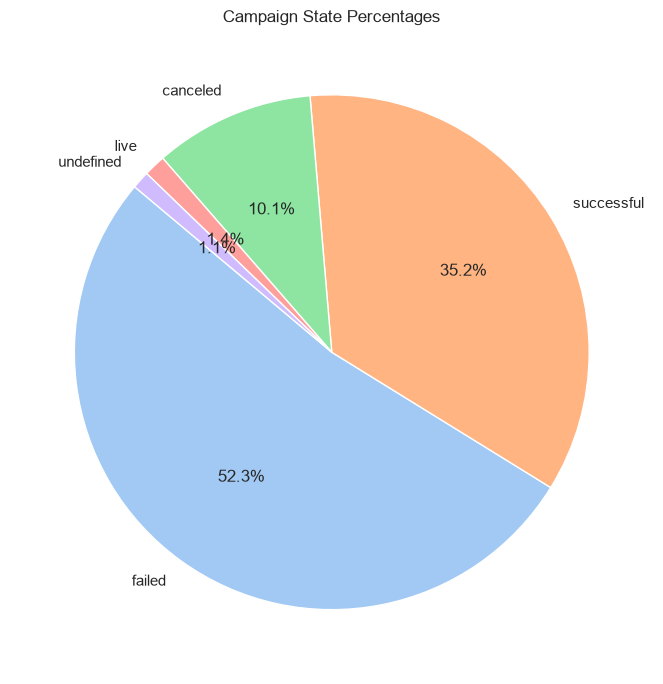

In [57]:

valid_states = ["failed", "successful", "canceled", "live", "undefined"]

state_counts = df[df["state"].isin(valid_states)]["state"].value_counts()

colors=sns.color_palette("pastel")[0:len(state_counts)] 

plt.figure(figsize=(9, 7))

plt.pie(
    state_counts.values,
    labels=state_counts.index,
    colors= colors,
    autopct="%1.1f%%",
    startangle=140,
)

plt.title("Campaign State Percentages")
plt.tight_layout()
plt.show()


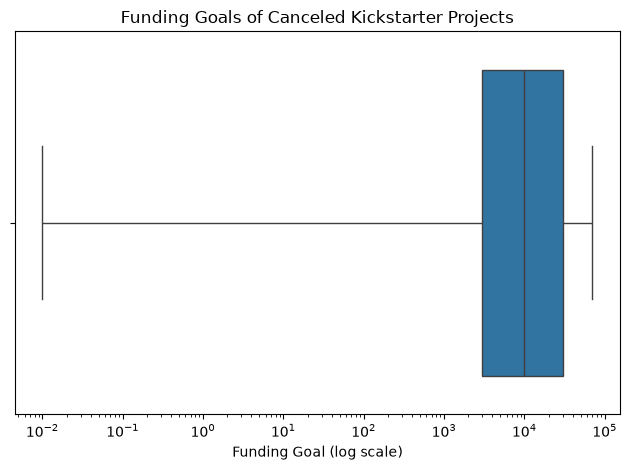

In [42]:
import matplotlib.ticker as ticker

ax = sns.boxplot(
    data=canceled,
    x="goal",
    showfliers=False
)

ax.set_xscale("log")
ax.xaxis.set_major_locator(ticker.LogLocator(base=10))
ax.xaxis.set_major_formatter(ticker.LogFormatterMathtext(base=10))

ax.set_title("Funding Goals of Canceled Kickstarter Projects")
ax.set_xlabel("Funding Goal (log scale)")

plt.tight_layout()
plt.show()

In [14]:
# Create a separate DataFrame for our analysis
analysis_df = df.copy()

# Remove extra columns created by inconsistent CSV rows
analysis_df = analysis_df.loc[
    :, ~analysis_df.columns.str.startswith("Unnamed")
].copy()

# Remove spaces from text fields
for col in ["state", "launched", "deadline"]:
    analysis_df[col] = analysis_df[col].astype("string").str.strip()

# Keep projects with clear completed outcomes
analysis_df = analysis_df[
    analysis_df["state"].isin(["successful", "failed"])
].copy()

# Convert campaign dates
analysis_df["launched"] = pd.to_datetime(
    analysis_df["launched"], errors="coerce"
)
analysis_df["deadline"] = pd.to_datetime(
    analysis_df["deadline"], errors="coerce"
)

# Calculate campaign duration in days
analysis_df["campaign_days"] = (
    analysis_df["deadline"] - analysis_df["launched"]
).dt.total_seconds() / (24 * 60 * 60)

# Keep records with valid, positive campaign durations
analysis_df = analysis_df[
    analysis_df["campaign_days"].notna()
    & (analysis_df["campaign_days"] > 0)
].copy()

print("Projects available for analysis:", len(analysis_df))
print("\nOutcome counts:")
print(analysis_df["state"].value_counts())
print("\nCampaign duration summary:")
print(analysis_df["campaign_days"].describe())

Projects available for analysis: 281302

Outcome counts:
state
failed        168221
successful    113081
Name: count, dtype: Int64

Campaign duration summary:
count    281302.000000
mean         34.159813
std          12.890952
min           1.000000
25%          30.000000
50%          30.000000
75%          36.941071
max          92.000000
Name: campaign_days, dtype: float64


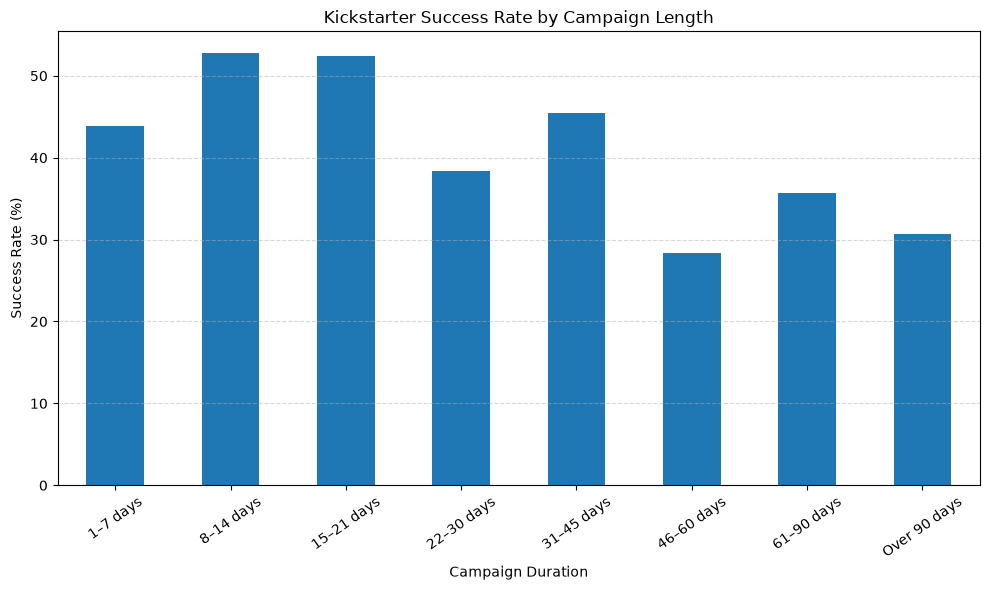

In [15]:
# Group campaign durations into ranges
bins = [0, 7, 14, 21, 30, 45, 60, 90, float("inf")]
labels = [
    "1–7 days", "8–14 days", "15–21 days",
    "22–30 days", "31–45 days", "46–60 days",
    "61–90 days", "Over 90 days"
]

analysis_df["duration_group"] = pd.cut(
    analysis_df["campaign_days"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Calculate success rate for each duration group
success_rates = (
    analysis_df.groupby("duration_group", observed=False)["state"]
    .apply(lambda states: (states == "successful").mean() * 100)
    .dropna()
)

ax = success_rates.plot(kind="bar", figsize=(10, 6))

ax.set_title("Kickstarter Success Rate by Campaign Length")
ax.set_xlabel("Campaign Duration")
ax.set_ylabel("Success Rate (%)")
ax.tick_params(axis="x", rotation=35)
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

The graph compares Kickstarter success rates across different campaign durations. Campaigns lasting 8–14 days and 15–21 days have the highest success rates, at approximately 53%. In comparison, campaigns lasting 46–60 days have the lowest success rate, at about 28%. The graph suggests that shorter campaigns may be associated with higher success rates in this dataset. However, this is an initial observation and does not prove that shorter campaigns cause projects to succeed. Other factors, such as funding goals, project categories, and audience interest, may also influence the results.


In [70]:
# Calculate variance and other spread measures for campaign durations
duration_series = analysis_df["campaign_days"].astype(float)

var_days = duration_series.var()
std_days = duration_series.std()
min_days = duration_series.min()
max_days = duration_series.max()
range_days = max_days - min_days
q1_days = duration_series.quantile(0.25)
q3_days = duration_series.quantile(0.75)
iqr_days = q3_days - q1_days

print(f"Variance: {var_days:.2f} days^2")
print(f"Standard deviation: {std_days:.2f} days")
print(f"Minimum: {min_days:.2f} days")
print(f"Maximum: {max_days:.2f} days")
print(f"Range: {range_days:.2f} days")
print(f"Q1: {q1_days:.2f} days")
print(f"Q3: {q3_days:.2f} days")
print(f"IQR: {iqr_days:.2f} days")

# Also show a quick summary
display(duration_series.describe())

Variance: 166.18 days^2
Standard deviation: 12.89 days
Minimum: 1.00 days
Maximum: 92.00 days
Range: 91.00 days
Q1: 30.00 days
Q3: 36.94 days
IQR: 6.94 days


count    281302.000000
mean         34.159813
std          12.890952
min           1.000000
25%          30.000000
50%          30.000000
75%          36.941071
max          92.000000
Name: campaign_days, dtype: float64

/var/folders/cx/1bd5ng0x13sfdp4d82d7wfk40000gn/T/ipykernel_3642/3450677606.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(


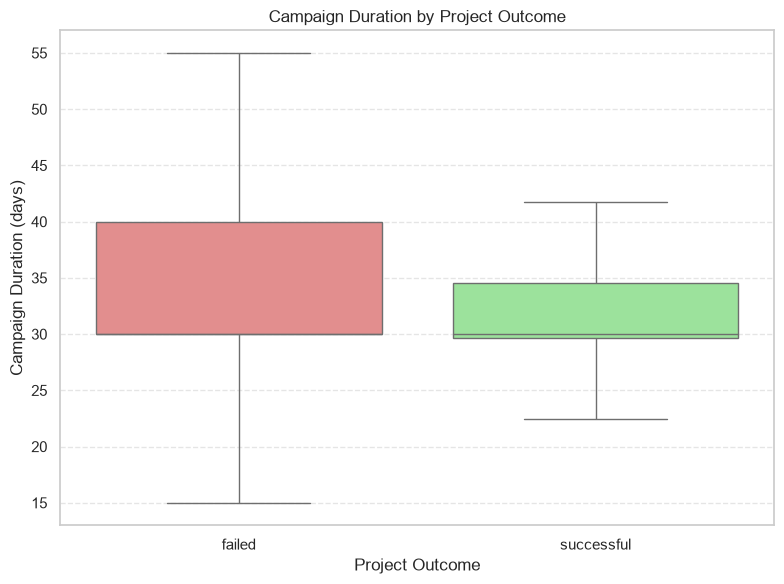

In [76]:
plot_df = analysis_df[analysis_df["state"].isin(["failed", "successful"])].copy()

plt.figure(figsize=(8, 6))

ax = sns.boxplot(
    data=plot_df,
    x="state",
    y="campaign_days",
    order=["failed", "successful"],
    palette={"failed": "lightcoral", "successful": "lightgreen"},
    showfliers=False
)

ax.set_title("Campaign Duration by Project Outcome")
ax.set_xlabel("Project Outcome")
ax.set_ylabel("Campaign Duration (days)")
ax.grid(True, axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [59]:
# Calculate the Pearson correlation coefficient
# Convert duration groups to ordered numeric values and correlate with a binary success outcome
duration_order = list(success_rates.index)

duration_numeric = pd.Categorical(
    analysis_df["duration_group"],
    categories=duration_order,
    ordered=True
).codes

success_numeric = analysis_df["state"].map({"failed": 0, "successful": 1})

correlation = pd.Series(duration_numeric, index=analysis_df.index).corr(success_numeric)

print("Correlation coefficient:", round(correlation, 4))

Correlation coefficient: -0.0716


In [16]:
# Create a separate DataFrame for funding-goal analysis
goal_df = analysis_df.copy()

# Convert funding goal to numeric values
goal_df["goal"] = pd.to_numeric(goal_df["goal"], errors="coerce")

# Keep only valid, positive funding goals
goal_df = goal_df[
    goal_df["goal"].notna() & (goal_df["goal"] > 0)
].copy()

print("Projects available:", len(goal_df))
print("\nFunding goal summary:")
print(goal_df["goal"].describe())

Projects available: 281302

Funding goal summary:
count    2.813020e+05
mean     4.183306e+04
std      1.044424e+06
min      1.000000e-02
25%      2.000000e+03
50%      5.000000e+03
75%      1.500000e+04
max      1.000000e+08
Name: goal, dtype: float64


In [17]:
import numpy as np

# Create funding-goal ranges
bins = [0, 1000, 5000, 10000, 25000, 50000, 100000, float("inf")]
labels = [
    "$1–$1,000",
    "$1,001–$5,000",
    "$5,001–$10,000",
    "$10,001–$25,000",
    "$25,001–$50,000",
    "$50,001–$100,000",
    "Over $100,000"
]

goal_df["goal_range"] = pd.cut(
    goal_df["goal"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Calculate success rate for each funding-goal range
goal_success_rates = (
    goal_df.groupby("goal_range", observed=False)["state"]
    .apply(lambda states: (states == "successful").mean() * 100)
    .dropna()
)

print(goal_success_rates.round(2))

goal_range
$1–$1,000           52.84
$1,001–$5,000       46.54
$5,001–$10,000      38.93
$10,001–$25,000     33.41
$25,001–$50,000     24.70
$50,001–$100,000    16.74
Over $100,000        8.07
Name: state, dtype: float64


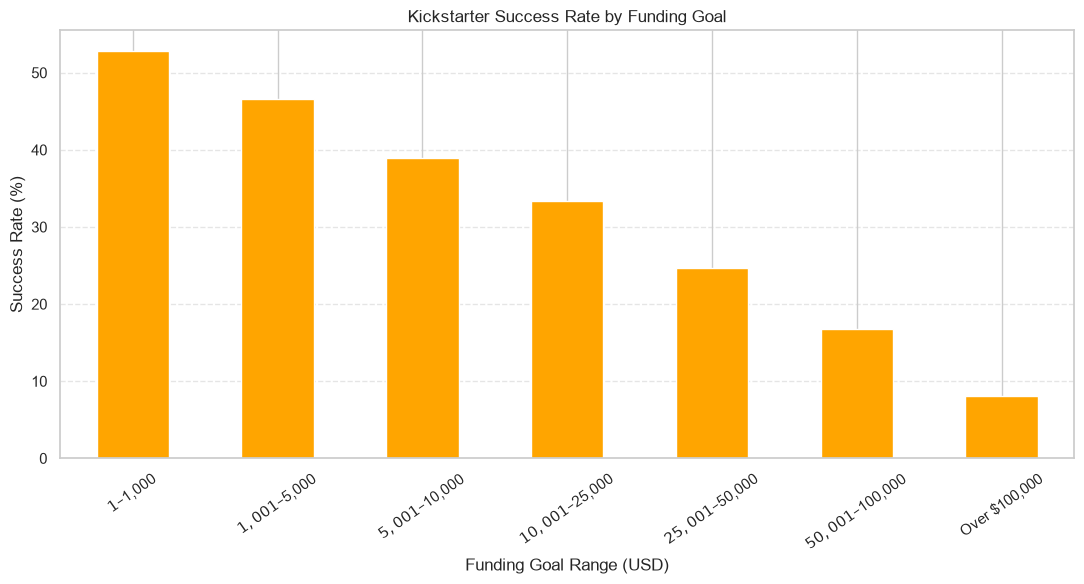

In [64]:
ax = goal_success_rates.plot(
    kind="bar", color="orange",
    figsize=(11, 6)
)

ax.set_title("Kickstarter Success Rate by Funding Goal")
ax.set_xlabel("Funding Goal Range (USD)")
ax.set_ylabel("Success Rate (%)")
ax.tick_params(axis="x", rotation=35)
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

The graph shows that Kickstarter success rates decrease as funding goals increase. Projects with goals between $1 and $1,000 have the highest success rate, at 52.84%, while projects with goals above $100,000 have the lowest rate, at 8.07%. This pattern suggests that projects with lower funding goals are more likely to succeed in this dataset. One possible explanation is that smaller goals may be easier for creators to reach. However, these results do not prove that lower goals directly cause success, because other factors, such as project category, campaign length, and audience interest, may also affect the outcome.


In [66]:
# Convert funding goal to numeric and success to a binary outcome
goal_numeric = pd.to_numeric(analysis_df["goal"], errors="coerce")
success_binary = analysis_df["state"].map({"failed": 0, "successful": 1})

# Keep only rows with valid values
valid = goal_numeric.notna() & success_binary.notna()

goal_success_corr = pd.Series(goal_numeric[valid].to_numpy()).corr(
    pd.Series(success_binary[valid].to_numpy())
)

print(f"Correlation coefficient between funding goal and success: {goal_success_corr:.4f}")

Correlation coefficient between funding goal and success: -0.0253


In [19]:
# Create a separate DataFrame for launch-timing analysis
launch_df = analysis_df.copy()

# Remove rows with missing launch dates
launch_df = launch_df.dropna(subset=["launched"]).copy()

# Extract launch month
launch_df["launch_month"] = launch_df["launched"].dt.month

# Map month numbers to names
month_names = {
    1: "January", 2: "February", 3: "March",
    4: "April", 5: "May", 6: "June",
    7: "July", 8: "August", 9: "September",
    10: "October", 11: "November", 12: "December"
}

launch_df["launch_month_name"] = launch_df["launch_month"].map(month_names)

print("Projects included:", len(launch_df))
print("\nLaunch month counts:")
print(launch_df["launch_month_name"].value_counts().reindex(month_names.values()))

Projects included: 281302

Launch month counts:
launch_month_name
January      20475
February     22662
March        25386
April        24676
May          24827
June         24928
July         28276
August       24536
September    23782
October      24898
November     21674
December     15182
Name: count, dtype: int64


In [20]:
monthly_success_rates = (
    launch_df.groupby("launch_month", sort=True)["state"]
    .apply(lambda states: (states == "successful").mean() * 100)
)

monthly_success_rates.index = [
    month_names[month] for month in monthly_success_rates.index
]

print("Success rate by launch month (%):")
print(monthly_success_rates.round(2))

Success rate by launch month (%):
January      38.38
February     41.92
March        42.51
April        42.32
May          41.48
June         40.63
July         36.00
August       37.54
September    40.52
October      41.80
November     40.91
December     37.94
Name: state, dtype: float64


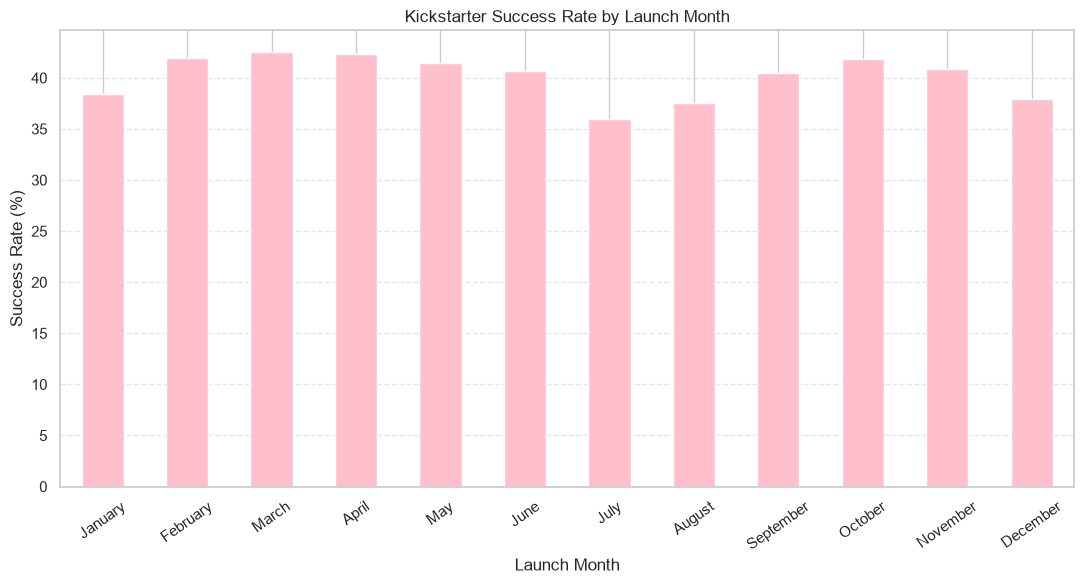

In [68]:
ax = monthly_success_rates.plot(
    kind="bar",
    color="pink",
    figsize=(11, 6)
)

ax.set_title("Kickstarter Success Rate by Launch Month")
ax.set_xlabel("Launch Month")
ax.set_ylabel("Success Rate (%)")
ax.tick_params(axis="x", rotation=35)
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

The graph compares Kickstarter success rates across the twelve launch months. March has the highest success rate at 42.51%, followed closely by April at 42.32%. July has the lowest success rate at 36.00%. The difference suggests that launch timing may be associated with project success, although the variation across months is relatively small. These results do not establish that launching in a particular month causes a project to succeed. Other factors, including funding goals, campaign duration, project category, and audience interest, may also influence success.


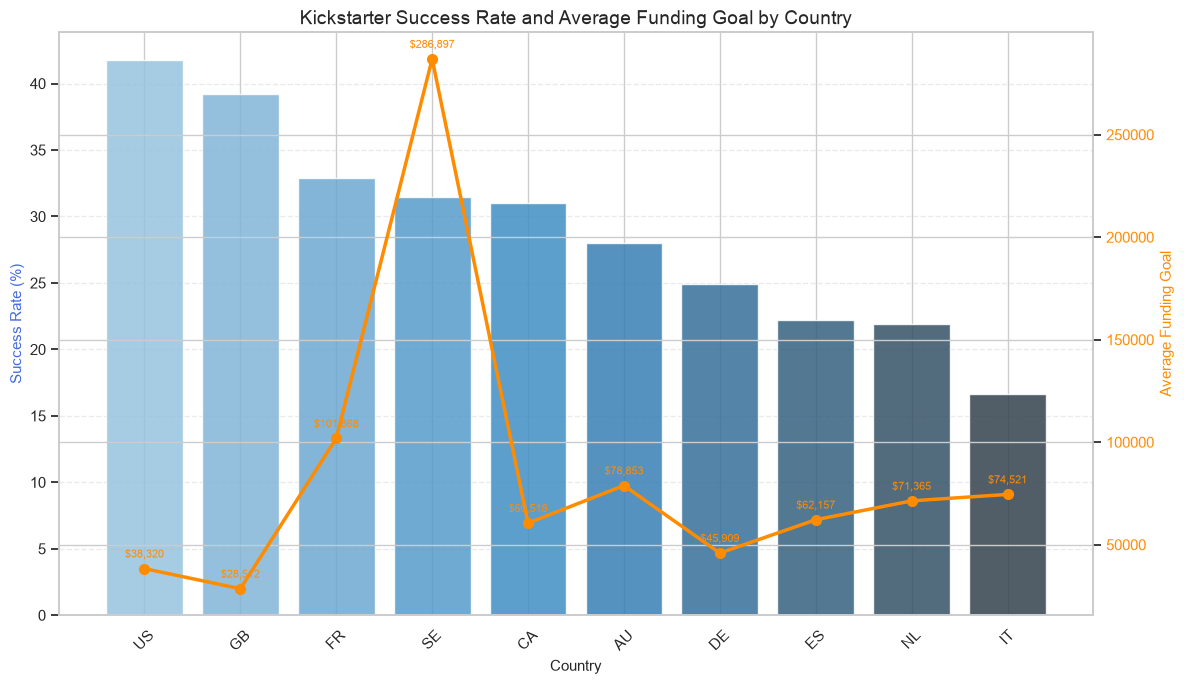

In [79]:
# Success rate and average funding goal by country
country_df = analysis_df[
    analysis_df["country"].notna() & analysis_df["state"].isin(["successful", "failed"])
].copy()

country_df["goal"] = pd.to_numeric(country_df["goal"], errors="coerce")

country_stats = (
    country_df.groupby("country")
    .agg(
        success_rate=("state", lambda s: (s == "successful").mean() * 100),
        avg_goal=("goal", "mean"),
        project_count=("ID", "count")
    )
    .sort_values(["project_count", "success_rate"], ascending=[False, False])
    .head(10)
    .reset_index()
)

country_stats = country_stats.sort_values("success_rate", ascending=False)

fig, ax1 = plt.subplots(figsize=(12, 7))

bar_colors = sns.color_palette("Blues_d", n_colors=len(country_stats))
ax1.bar(country_stats["country"], country_stats["success_rate"], color=bar_colors, alpha=0.85)
ax1.set_ylabel("Success Rate (%)", color="royalblue", fontsize=11)
ax1.set_xlabel("Country", fontsize=11)
ax1.set_title("Kickstarter Success Rate and Average Funding Goal by Country", fontsize=14)
ax1.tick_params(axis="x", rotation=45)
ax1.grid(axis="y", linestyle="--", alpha=0.4)
ax1.set_axisbelow(True)

ax2 = ax1.twinx()
ax2.plot(
    country_stats["country"],
    country_stats["avg_goal"],
    color="darkorange",
    marker="o",
    linewidth=2.5,
    markersize=7,
    label="Average Goal"
)
ax2.set_ylabel("Average Funding Goal", color="darkorange", fontsize=11)
ax2.tick_params(axis="y", labelcolor="darkorange")

for i, val in enumerate(country_stats["avg_goal"]):
    ax2.annotate(
        f"${val:,.0f}",
        (i, val),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        color="darkorange",
        fontsize=8
    )

plt.tight_layout()
plt.show()